# Stage 9: Final Analysis and Visualization

This notebook recomputes summaries and displays figures from the saved Stage 4-8 metric CSVs and compact provenance metadata in `results/`. Raw datasets, saved split-index files, prediction caches, trained weights, and model inference are not required. When cache or checkpoint folders are present, their compact metadata files are preferred sources; the committed copies in `results/` are sufficient fallbacks.

The three fixed splits (seeds 42, 43, 44) overlap. Their mean and sample standard deviation describe sensitivity to split choice, not independent replications or confidence intervals. The split-integrity check reconstructs the Stage 1 partitions in memory using those seeds.

Outputs are six figures, including the full 45-pair label-shift overview (PNG and PDF), Stage 9 summary CSVs, and a provenance manifest. By default, `REGENERATE_FIGURES=False`: existing figure files are retained, missing figures are saved, and newly calculated plots are displayed. Set `REGENERATE_FIGURES=True` in the setup cell to replace existing PNG/PDF exports.

Checks cover source row counts, fixed priors, baseline reconstruction, split integrity, table/source agreement, and figure labels. Stage 4-8 experimental CSVs are read-only inputs.

## 1. Load saved results

The project root is detected from either the repository directory or its notebooks directory. The experiment mapping is fixed: two base models, three conformal methods, three split seeds, and the nine approved corruption/severity conditions. Label shift uses seven fixed target priors: balanced plus three levels for each of two emphasized class pairs. Stage 9 reads compact saved results; it does not need raw data, prediction NPZ caches, or training checkpoints.


In [ ]:
from pathlib import Path
import hashlib
import json
import shutil
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((p.resolve() for p in candidates if (p / "results").is_dir() and (p / "notebooks").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate the project root from the current notebook directory.")
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
SPLITS_DIR = PROJECT_ROOT / "data" / "splits"
CACHE_DIR = PROJECT_ROOT / "cached_outputs" / "stage4_predictions"

# Leave False for ordinary runs. Set True only when you explicitly want to
# regenerate figures; existing files are copied to a verified backup first.
REGENERATE_FIGURES = False
FIGURE_BACKUP_ROOT = FIGURES_DIR / "backups"

MODELS = ["standard_resnet18", "augmix_resnet18"]
METHODS = ["LAC", "APS", "RAPS"]
SPLIT_SEEDS = [42, 43, 44]
CONDITIONS = ["gaussian_noise", "defocus_blur", "brightness"]
SEVERITIES = [1, 3, 5]
NOMINAL_COVERAGE = 0.90
MODEL_LABELS = {"standard_resnet18": "Standard ResNet-18", "augmix_resnet18": "AugMix ResNet-18"}
METHOD_LABELS = {"LAC": "LAC", "APS": "APS", "RAPS": "RAPS"}
CONDITION_LABELS = {"gaussian_noise": "Gaussian noise", "defocus_blur": "Defocus blur", "brightness": "Brightness"}
method_colors = dict(zip(METHODS, plt.rcParams["axes.prop_cycle"].by_key()["color"][:3]))

cache_accuracy_primary = CACHE_DIR / "cache_accuracy_summary.csv"
cache_accuracy_fallback = RESULTS_DIR / "stage4_cache_accuracy_summary.csv"
if cache_accuracy_primary.is_file():
    cache_accuracy_path = cache_accuracy_primary
elif cache_accuracy_fallback.is_file():
    cache_accuracy_path = cache_accuracy_fallback
else:
    raise FileNotFoundError("Stage 4 accuracy summary is missing from both cached_outputs/ and results/.")

src = {
    "cache_accuracy": cache_accuracy_path,
    "clean": {m: RESULTS_DIR / f"{m.lower()}_clean_metrics.csv" for m in METHODS},
    "corruption": {m: RESULTS_DIR / f"{m.lower()}_corruption_metrics.csv" for m in METHODS},
    "label_split": RESULTS_DIR / "label_shift_split_results.csv",
    "label_summary": RESULTS_DIR / "label_shift_summary_mean_std.csv",
    "class_conditional": RESULTS_DIR / "label_shift_class_conditional_metrics.csv",
    "target_priors": RESULTS_DIR / "label_shift_target_priors.csv",
    "baseline_audit": RESULTS_DIR / "label_shift_baseline_reconstruction_audit.csv",
    "monte_carlo": RESULTS_DIR / "label_shift_monte_carlo_validation.csv",
}
for path in [src["cache_accuracy"], src["label_split"], src["label_summary"], src["class_conditional"], src["target_priors"], src["baseline_audit"], src["monte_carlo"], *src["clean"].values(), *src["corruption"].values()]:
    if not path.is_file():
        raise FileNotFoundError(f"Required saved input is missing: {path}")

cache_accuracy = pd.read_csv(src["cache_accuracy"])
clean = pd.concat([pd.read_csv(path).assign(method=method) for method, path in src["clean"].items()], ignore_index=True)
corruption = pd.concat([pd.read_csv(path).assign(method=method) for method, path in src["corruption"].items()], ignore_index=True)
label_split = pd.read_csv(src["label_split"])
label_summary = pd.read_csv(src["label_summary"])
class_conditional = pd.read_csv(src["class_conditional"])
target_priors = pd.read_csv(src["target_priors"])
baseline_audit = pd.read_csv(src["baseline_audit"])
monte_carlo = pd.read_csv(src["monte_carlo"])

print(f"Project root: {PROJECT_ROOT}")
print(f"Stage 4 accuracy source: {cache_accuracy_path.relative_to(PROJECT_ROOT)}")
print(f"Pandas {pd.__version__}; NumPy {np.__version__}; Matplotlib {plt.matplotlib.__version__}")
print({
    "Stage 4 cache accuracy": len(cache_accuracy), "clean rows": len(clean),
    "corruption rows": len(corruption), "label-shift split rows": len(label_split),
    "label-shift summary rows": len(label_summary), "class-conditional rows": len(class_conditional),
    "target-prior rows": len(target_priors), "baseline audit rows": len(baseline_audit),
    "Monte Carlo validation rows": len(monte_carlo),
})


Project root: E:\unc\2026f\store566\final project
Stage 4 accuracy source: cached_outputs\stage4_predictions\cache_accuracy_summary.csv
Pandas 3.0.6; NumPy 2.5.3; Matplotlib 3.11.2
{'Stage 4 cache accuracy': 20, 'clean rows': 18, 'corruption rows': 162, 'label-shift split rows': 126, 'label-shift summary rows': 42, 'class-conditional rows': 180, 'target-prior rows': 70, 'baseline audit rows': 18, 'Monte Carlo validation rows': 4}


## 2. Validate row counts, mappings, splits, and baseline reconstruction

Each method must have six clean model/split rows and 54 corruption rows. The saved Stage 8 baseline reconstruction must match the original clean metrics to numerical precision. The final traceability section recreates each Stage 1 partition in memory from its fixed seed and checks that calibration/evaluation indices are disjoint, 5,000/5,000, and cover all 10,000 test indices; it does not load split-index files.

In [ ]:
expected_clean = {(m, s) for m in MODELS for s in SPLIT_SEEDS}
expected_corrupt = {(m, s, c, v) for m in MODELS for s in SPLIT_SEEDS for c in CONDITIONS for v in SEVERITIES}
assert len(cache_accuracy) == 20
assert set(cache_accuracy.model_key.unique()) == set(MODELS)
assert cache_accuracy.groupby("model_key").size().eq(10).all()
assert set(cache_accuracy.condition.unique()) == {"clean", *CONDITIONS}

for method in METHODS:
    part = clean[clean.method == method]
    assert len(part) == 6
    assert set(zip(part.model_key, part.split_seed.astype(int))) == expected_clean
    part = corruption[corruption.method == method]
    assert len(part) == 54
    assert set(zip(part.model_key, part.split_seed.astype(int), part.condition, part.severity.astype(int))) == expected_corrupt
assert len(clean) == 18 and len(corruption) == 162
assert len(label_split) == 126 and len(label_summary) == 42 and len(class_conditional) == 180
assert len(target_priors) == 70 and len(baseline_audit) == 18 and len(monte_carlo) == 4
assert set(clean.method.unique()) == set(METHODS)
assert set(corruption.method.unique()) == set(METHODS)
assert set(label_split.model_key.unique()) == set(MODELS)
assert set(label_split.method.unique()) == set(METHODS)
assert set(label_split.split_seed.astype(int).unique()) == set(SPLIT_SEEDS)
assert baseline_audit.matches_saved_metrics.astype(bool).all()
audit_errors = [c for c in baseline_audit.columns if c.endswith("_abs_error")]
assert baseline_audit[audit_errors].to_numpy(float).max() < 1e-12

top1_wide = clean.pivot(index=["model_key", "split_seed"], columns="method", values="top1_accuracy")
assert np.allclose(top1_wide.to_numpy(), top1_wide.iloc[:, [0]].to_numpy())
# Recreate the Stage 1 partition rule in memory; split files are generated artifacts, not analysis inputs.
for seed in SPLIT_SEEDS:
    permutation = np.random.default_rng(seed).permutation(10_000)
    calibration_indices = permutation[:5_000]
    evaluation_indices = permutation[5_000:]
    assert calibration_indices.size == evaluation_indices.size == 5_000
    assert np.intersect1d(calibration_indices, evaluation_indices).size == 0
    assert np.array_equal(np.sort(np.concatenate([calibration_indices, evaluation_indices])), np.arange(10_000))
print("Expected rows and combinations, baseline audit, and deterministic split rule: PASS")
print("Maximum baseline reconstruction errors:", baseline_audit[audit_errors].max().to_dict())

Expected rows and combinations, baseline audit, and deterministic split rule: PASS
Maximum baseline reconstruction errors: {'empirical_coverage_abs_error': 1.1102230246251563e-16, 'average_set_size_abs_error': 2.220446049250313e-16, 'empty_set_proportion_abs_error': 1.3877787807814457e-17, 'top1_accuracy_abs_error': 1.1102230246251563e-16}


## 3. Verify the illustrative target priors

The seven detailed contrasts use balanced plus cat/dog (IDs 3 and 5) and airplane/automobile (IDs 0 and 1) emphasis at three levels. Probabilities are checked against their fixed definitions and must be nonnegative and sum to one. The balanced prior is exactly 0.10 per class and may differ from a split's empirical class proportions. The full-rotation overview later reads all 136 priors' results from Stage 8.

In [ ]:
def expected_prior(scenario):
    p = np.full(10, 0.10)
    if scenario == "balanced":
        return p
    family, level = scenario.rsplit("_", 1)
    heavy = {"mild": 0.15, "moderate": 0.20, "severe": 0.30}[level]
    emphasized = {"cat_dog": [3, 5], "airplane_automobile": [0, 1]}[family]
    p[:] = (1 - 2 * heavy) / 8
    p[emphasized] = heavy
    return p

expected_scenarios = {
    "balanced", "cat_dog_mild", "cat_dog_moderate", "cat_dog_severe",
    "airplane_automobile_mild", "airplane_automobile_moderate", "airplane_automobile_severe",
}
assert set(target_priors.scenario.unique()) == expected_scenarios
for scenario, rows in target_priors.groupby("scenario"):
    rows = rows.sort_values("class_id")
    p = rows.target_probability.to_numpy(float)
    assert len(rows) == 10 and rows.class_id.astype(int).tolist() == list(range(10))
    assert np.isfinite(p).all() and (p >= 0).all() and np.isclose(p.sum(), 1)
    assert np.allclose(p, expected_prior(scenario), atol=1e-12)
prior_table = target_priors.pivot(index="scenario", columns="class_name", values="target_probability")
display(prior_table.sort_index().style.format("{:.3f}"))
print("All seven scenario definitions match the frozen priors.")
print("Monte Carlo audit (finite-sample check; exact equality is not expected):")
display(monte_carlo)

All seven scenario definitions match the frozen priors.
Monte Carlo audit (finite-sample check; exact equality is not expected):


class_name,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck
scenario,,,,,,,,,,
airplane_automobile_mild,0.150,0.150,0.087,0.087,0.087,0.087,0.087,0.087,0.087,0.087
airplane_automobile_moderate,0.200,0.200,0.075,0.075,0.075,0.075,0.075,0.075,0.075,0.075
airplane_automobile_severe,0.300,0.300,0.050,0.050,0.050,0.050,0.050,0.050,0.050,0.050
balanced,0.100,0.100,0.100,0.100,0.100,0.100,0.100,0.100,0.100,0.100
cat_dog_mild,0.087,0.087,0.087,0.150,0.087,0.150,0.087,0.087,0.087,0.087
cat_dog_moderate,0.075,0.075,0.075,0.200,0.075,0.200,0.075,0.075,0.075,0.075
cat_dog_severe,0.050,0.050,0.050,0.300,0.050,0.300,0.050,0.050,0.050,0.050


,metric,analytical_weighted_estimate,monte_carlo_estimate,difference,expected_sampling_se,absolute_difference_in_se
0,empirical_coverage,0.891805,0.8880,-0.003805,0.004393,0.866167
1,average_set_size,0.999676,0.9966,-0.003076,0.005833,0.527316
2,empty_set_rate,0.070279,0.0714,0.001121,0.003615,0.309989
3,top1_accuracy,0.938754,0.9392,0.000446,0.003391,0.131581


## 4. Prepare split-specific tables and three-split summaries

Top-1 accuracy, empirical coverage, coverage gap, average set size, and empty-set rate are carried forward from the saved Stage 4–8 outputs. The aggregation uses the arithmetic mean and sample SD (ddof=1) across the three overlapping split sensitivity checks.

In [ ]:
def summarize(frame, keys, metrics):
    named = {f"{metric}_{stat}": (metric, stat) for metric in metrics for stat in ["mean", "std"]}
    return frame.groupby(keys, as_index=False).agg(**named)

clean_split_metrics = clean.sort_values(["model_key", "method", "split_seed"]).reset_index(drop=True)
metrics = ["top1_accuracy", "empirical_coverage", "coverage_gap", "average_set_size", "empty_set_proportion"]
clean_summary = summarize(clean_split_metrics, ["model_key", "method"], metrics)
corruption_split_metrics = corruption.sort_values(["model_key", "method", "condition", "severity", "split_seed"]).reset_index(drop=True)
corruption_summary = summarize(corruption_split_metrics, ["model_key", "method", "condition", "severity"], metrics)
severity5_summary = corruption_summary[corruption_summary.severity == 5].copy()
assert len(clean_split_metrics) == 18 and len(clean_summary) == 6
assert len(corruption_split_metrics) == 162 and len(corruption_summary) == 54 and len(severity5_summary) == 18
assert not clean_split_metrics.duplicated(["model_key", "method", "split_seed"]).any()
assert not corruption_split_metrics.duplicated(["model_key", "method", "split_seed", "condition", "severity"]).any()

for _, row in clean_summary.iterrows():
    part = clean_split_metrics[(clean_split_metrics.model_key == row.model_key) & (clean_split_metrics.method == row.method)]
    for metric in metrics:
        assert np.isclose(row[f"{metric}_mean"], part[metric].mean())
        assert np.isclose(row[f"{metric}_std"], part[metric].std(ddof=1))

label_summary["scenario_family"] = label_summary.scenario.map(lambda x: "balanced" if x == "balanced" else x.rsplit("_", 1)[0])
label_summary["scenario_level"] = label_summary.scenario.map(lambda x: "balanced" if x == "balanced" else x.rsplit("_", 1)[1])
label_summary["scenario_order"] = label_summary.scenario_level.map({"balanced": 0, "mild": 1, "moderate": 2, "severe": 3})
label_summary_main = label_summary.sort_values(["scenario_family", "scenario_order", "model_key", "method"]).reset_index(drop=True)
assert len(label_summary_main) == 42

# Reconstruct every saved aggregate summary directly from split-specific rows.
for _, row in corruption_summary.iterrows():
    part = corruption_split_metrics[(corruption_split_metrics.model_key == row.model_key) & (corruption_split_metrics.method == row.method) & (corruption_split_metrics.condition == row.condition) & (corruption_split_metrics.severity == row.severity)]
    for metric in metrics:
        assert np.isclose(row[f"{metric}_mean"], part[metric].mean())
        assert np.isclose(row[f"{metric}_std"], part[metric].std(ddof=1))
label_source_summary = summarize(label_split, ["model_key", "method", "scenario"], ["empirical_coverage", "coverage_gap", "average_set_size", "empty_set_rate", "top1_accuracy"])
label_check = label_summary_main.merge(label_source_summary, on=["model_key", "method", "scenario"], suffixes=("_saved", "_recomputed"), validate="one_to_one")
for metric in ["empirical_coverage", "coverage_gap", "average_set_size", "empty_set_rate", "top1_accuracy"]:
    assert np.allclose(label_check[f"{metric}_mean_saved"], label_check[f"{metric}_mean_recomputed"])
    assert np.allclose(label_check[f"{metric}_std_saved"], label_check[f"{metric}_std_recomputed"])
print("Clean, corruption, label-shift summaries reconstruct from split-specific source rows: PASS")

clean_show = ["model_key", "method"] + [f"{m}_{s}" for m in metrics for s in ["mean", "std"]]
corrupt_show = ["model_key", "method", "condition"] + [f"{m}_{s}" for m in metrics for s in ["mean", "std"]]
print("Clean results: mean ± sample SD")
display(clean_summary[clean_show].style.format({c: "{:.4f}" for c in clean_show[2:]}))
print("Severity-5 results: mean ± sample SD")
display(severity5_summary[corrupt_show].sort_values(["condition", "model_key", "method"]).style.format({c: "{:.4f}" for c in corrupt_show[3:]}))

label_show = ["model_key", "method", "scenario", "empirical_coverage_mean", "empirical_coverage_std", "average_set_size_mean", "average_set_size_std", "empty_set_rate_mean", "empty_set_rate_std", "top1_accuracy_mean", "top1_accuracy_std"]
print("Label-shift results: analytical reweighting, mean ± sample SD")
display(label_summary_main[label_show].style.format({c: "{:.4f}" for c in label_show[3:]}))

Clean, corruption, label-shift summaries reconstruct from split-specific source rows: PASS
Clean results: mean ± sample SD
Severity-5 results: mean ± sample SD
Label-shift results: analytical reweighting, mean ± sample SD


,model_key,method,top1_accuracy_mean,top1_accuracy_std,empirical_coverage_mean,empirical_coverage_std,coverage_gap_mean,coverage_gap_std,average_set_size_mean,average_set_size_std,empty_set_proportion_mean,empty_set_proportion_std
0,augmix_resnet18,APS,0.9527,0.0005,0.9025,0.0102,-0.0025,0.0102,1.0297,0.0140,0.0752,0.0090
1,augmix_resnet18,LAC,0.9527,0.0005,0.9012,0.0021,-0.0012,0.0021,0.9174,0.0016,0.0826,0.0016
2,augmix_resnet18,RAPS,0.9527,0.0005,0.9019,0.0099,-0.0019,0.0099,1.0107,0.0118,0.0723,0.0090
3,standard_resnet18,APS,0.9507,0.0011,0.9017,0.0049,-0.0017,0.0049,0.9945,0.0043,0.0669,0.0063
4,standard_resnet18,LAC,0.9507,0.0011,0.9015,0.0067,-0.0015,0.0067,0.9182,0.0080,0.0818,0.0080
5,standard_resnet18,RAPS,0.9507,0.0011,0.9011,0.0049,-0.0011,0.0049,0.9831,0.0047,0.0645,0.0057


,model_key,method,condition,top1_accuracy_mean,top1_accuracy_std,empirical_coverage_mean,empirical_coverage_std,coverage_gap_mean,coverage_gap_std,average_set_size_mean,average_set_size_std,empty_set_proportion_mean,empty_set_proportion_std
2,augmix_resnet18,APS,brightness,0.9275,0.0011,0.8938,0.0072,0.0062,0.0072,1.0765,0.0138,0.0697,0.0071
11,augmix_resnet18,LAC,brightness,0.9275,0.0011,0.8621,0.0006,0.0379,0.0006,0.8863,0.0004,0.1137,0.0004
20,augmix_resnet18,RAPS,brightness,0.9275,0.0011,0.8915,0.0077,0.0085,0.0077,1.0503,0.0108,0.0671,0.0074
29,standard_resnet18,APS,brightness,0.9127,0.0029,0.8825,0.0041,0.0175,0.0041,1.0524,0.0105,0.0638,0.0052
38,standard_resnet18,LAC,brightness,0.9127,0.0029,0.8393,0.0037,0.0607,0.0037,0.8705,0.0046,0.1295,0.0046
47,standard_resnet18,RAPS,brightness,0.9127,0.0029,0.8805,0.0027,0.0195,0.0027,1.0298,0.0082,0.0613,0.0042
5,augmix_resnet18,APS,defocus_blur,0.9154,0.0022,0.8858,0.0079,0.0142,0.0079,1.0849,0.0166,0.0699,0.0076
14,augmix_resnet18,LAC,defocus_blur,0.9154,0.0022,0.8477,0.0020,0.0523,0.0020,0.8770,0.0016,0.1230,0.0016
23,augmix_resnet18,RAPS,defocus_blur,0.9154,0.0022,0.8837,0.0078,0.0163,0.0078,1.0561,0.0125,0.0667,0.0077
32,standard_resnet18,APS,defocus_blur,0.5787,0.0077,0.6707,0.0007,0.2293,0.0007,1.5169,0.0137,0.0350,0.0036


,model_key,method,scenario,empirical_coverage_mean,empirical_coverage_std,average_set_size_mean,average_set_size_std,empty_set_rate_mean,empty_set_rate_std,top1_accuracy_mean,top1_accuracy_std
0,augmix_resnet18,APS,airplane_automobile_mild,0.9019,0.0108,1.0229,0.0147,0.0768,0.0098,0.9554,0.0005
1,augmix_resnet18,LAC,airplane_automobile_mild,0.9048,0.0022,0.9203,0.0018,0.0797,0.0018,0.9554,0.0005
2,augmix_resnet18,RAPS,airplane_automobile_mild,0.9016,0.0108,1.0047,0.0128,0.0740,0.0099,0.9554,0.0005
3,standard_resnet18,APS,airplane_automobile_mild,0.9020,0.0059,0.9920,0.0049,0.0678,0.0068,0.9523,0.0012
4,standard_resnet18,LAC,airplane_automobile_mild,0.9040,0.0069,0.9200,0.0080,0.0800,0.0080,0.9523,0.0012
5,standard_resnet18,RAPS,airplane_automobile_mild,0.9017,0.0058,0.9810,0.0052,0.0656,0.0063,0.9523,0.0012
6,augmix_resnet18,APS,airplane_automobile_moderate,0.9015,0.0115,1.0163,0.0157,0.0783,0.0107,0.9579,0.0006
7,augmix_resnet18,LAC,airplane_automobile_moderate,0.9082,0.0028,0.9231,0.0023,0.0769,0.0023,0.9579,0.0006
8,augmix_resnet18,RAPS,airplane_automobile_moderate,0.9014,0.0117,0.9990,0.0137,0.0756,0.0108,0.9579,0.0006
9,standard_resnet18,APS,airplane_automobile_moderate,0.9023,0.0068,0.9895,0.0055,0.0687,0.0074,0.9540,0.0017


## 5. Class-conditional differences behind reweighting

Compare cat/dog (IDs 3 and 5) with its complementary eight classes, and airplane/automobile (IDs 0 and 1) with its complementary eight classes. Each pair and its complement must partition all ten classes without overlap.

For each split, verify the identity implied by the fixed balanced and severe priors: `C_severe - C_balanced = 0.4 * (mean coverage of emphasized two - mean coverage of complementary eight)`. This links the derived group contrasts to the Stage 8 label-shift results.

In [ ]:
CLASS_NAMES = {0: "airplane", 1: "automobile", 2: "bird", 3: "cat", 4: "deer", 5: "dog", 6: "frog", 7: "horse", 8: "ship", 9: "truck"}
ALL_CLASS_IDS = set(range(10))
CONTRASTS = {
    "cat_dog_vs_other_eight": {"emphasized": {3, 5}, "severe_scenario": "cat_dog_severe"},
    "airplane_automobile_vs_other_eight": {"emphasized": {0, 1}, "severe_scenario": "airplane_automobile_severe"},
}

group_rows = []
for (model, method, seed), class_rows in class_conditional.groupby(["model_key", "method", "split_seed"], sort=True):
    class_rows = class_rows.copy()
    class_rows["class_id"] = class_rows.class_id.astype(int)
    assert len(class_rows) == 10 and set(class_rows.class_id) == ALL_CLASS_IDS
    assert not class_rows.class_id.duplicated().any()
    class_coverage = class_rows.set_index("class_id").class_coverage

    for contrast_name, spec in CONTRASTS.items():
        emphasized = set(spec["emphasized"])
        complementary = ALL_CLASS_IDS - emphasized
        assert len(emphasized) == 2 and len(complementary) == 8
        assert emphasized.isdisjoint(complementary)
        assert emphasized | complementary == ALL_CLASS_IDS

        mean_emphasized = float(class_coverage.loc[sorted(emphasized)].mean())
        mean_complementary = float(class_coverage.loc[sorted(complementary)].mean())
        reconstructed_difference = 0.4 * (mean_emphasized - mean_complementary)

        label_rows = label_split[
            (label_split.model_key == model)
            & (label_split.method == method)
            & (label_split.split_seed.astype(int) == int(seed))
        ]
        balanced_rows = label_rows[label_rows.scenario == "balanced"]
        severe_rows = label_rows[label_rows.scenario == spec["severe_scenario"]]
        assert len(balanced_rows) == len(severe_rows) == 1
        observed_difference = float(severe_rows.iloc[0].empirical_coverage - balanced_rows.iloc[0].empirical_coverage)
        absolute_error = abs(observed_difference - reconstructed_difference)
        assert np.isclose(observed_difference, reconstructed_difference, rtol=0, atol=1e-12)

        group_rows.append({
            "model_key": model,
            "method": method,
            "split_seed": int(seed),
            "contrast": contrast_name,
            "emphasized_class_ids": ";".join(map(str, sorted(emphasized))),
            "emphasized_classes": ";".join(CLASS_NAMES[i] for i in sorted(emphasized)),
            "complementary_eight_class_ids": ";".join(map(str, sorted(complementary))),
            "complementary_eight_classes": ";".join(CLASS_NAMES[i] for i in sorted(complementary)),
            "mean_emphasized_class_coverage": mean_emphasized,
            "mean_complementary_eight_class_coverage": mean_complementary,
            "emphasized_minus_complementary_coverage": mean_emphasized - mean_complementary,
            "reconstructed_severe_minus_balanced_coverage": reconstructed_difference,
            "observed_severe_minus_balanced_coverage": observed_difference,
            "identity_absolute_error": absolute_error,
        })

group_split = pd.DataFrame(group_rows).sort_values(["model_key", "method", "split_seed", "contrast"]).reset_index(drop=True)
assert len(group_split) == 36
assert group_split.groupby(["model_key", "method", "split_seed"]).size().eq(2).all()

summary_metrics = [
    "mean_emphasized_class_coverage",
    "mean_complementary_eight_class_coverage",
    "emphasized_minus_complementary_coverage",
    "reconstructed_severe_minus_balanced_coverage",
    "observed_severe_minus_balanced_coverage",
    "identity_absolute_error",
]
group_summary = group_split.groupby(["model_key", "method", "contrast"], as_index=False).agg(
    **{f"{metric}_{stat}": (metric, stat) for metric in summary_metrics for stat in ["mean", "std"]}
)
assert len(group_summary) == 12
assert group_summary.identity_absolute_error_mean.max() < 1e-12
display(group_summary.style.format({c: "{:.6f}" for c in group_summary.columns if c.endswith(("_mean", "_std"))}))
print("Both emphasized pairs and their complementary eight-class groups partition all ten classes: PASS")
print("Balanced-to-severe coverage identity for every model/method/split/contrast: PASS (absolute tolerance 1e-12)")


Both emphasized pairs and their complementary eight-class groups partition all ten classes: PASS
Balanced-to-severe coverage identity for every model/method/split/contrast: PASS (absolute tolerance 1e-12)


,model_key,method,contrast,mean_emphasized_class_coverage_mean,mean_emphasized_class_coverage_std,mean_complementary_eight_class_coverage_mean,mean_complementary_eight_class_coverage_std,emphasized_minus_complementary_coverage_mean,emphasized_minus_complementary_coverage_std,reconstructed_severe_minus_balanced_coverage_mean,reconstructed_severe_minus_balanced_coverage_std,observed_severe_minus_balanced_coverage_mean,observed_severe_minus_balanced_coverage_std,identity_absolute_error_mean,identity_absolute_error_std
0,augmix_resnet18,APS,airplane_automobile_vs_other_eight,0.898791,0.016817,0.903258,0.009433,-0.004466,0.011862,-0.001787,0.004745,-0.001787,0.004745,0.000000,0.000000
1,augmix_resnet18,APS,cat_dog_vs_other_eight,0.900214,0.005303,0.902902,0.011506,-0.002688,0.006277,-0.001075,0.002511,-0.001075,0.002511,0.000000,0.000000
2,augmix_resnet18,LAC,airplane_automobile_vs_other_eight,0.929157,0.006914,0.894291,0.001587,0.034866,0.007350,0.013946,0.002940,0.013946,0.002940,0.000000,0.000000
3,augmix_resnet18,LAC,cat_dog_vs_other_eight,0.794511,0.013272,0.927953,0.001696,-0.133442,0.014705,-0.053377,0.005882,-0.053377,0.005882,0.000000,0.000000
4,augmix_resnet18,RAPS,airplane_automobile_vs_other_eight,0.900385,0.017622,0.902116,0.008517,-0.001731,0.011415,-0.000692,0.004566,-0.000692,0.004566,0.000000,0.000000
5,augmix_resnet18,RAPS,cat_dog_vs_other_eight,0.893313,0.004822,0.903884,0.011378,-0.010570,0.007465,-0.004228,0.002986,-0.004228,0.002986,0.000000,0.000000
6,standard_resnet18,APS,airplane_automobile_vs_other_eight,0.904220,0.012156,0.901014,0.003317,0.003206,0.009031,0.001282,0.003612,0.001282,0.003612,0.000000,0.000000
7,standard_resnet18,APS,cat_dog_vs_other_eight,0.873934,0.006711,0.908585,0.007707,-0.034651,0.013970,-0.013861,0.005588,-0.013861,0.005588,0.000000,0.000000
8,standard_resnet18,LAC,airplane_automobile_vs_other_eight,0.921118,0.011265,0.896674,0.006720,0.024444,0.010213,0.009777,0.004085,0.009777,0.004085,0.000000,0.000000
9,standard_resnet18,LAC,cat_dog_vs_other_eight,0.824249,0.002372,0.920891,0.008658,-0.096642,0.010090,-0.038657,0.004036,-0.038657,0.004036,0.000000,0.000000


## 6. Main figures: corruption and coverage-efficiency

Figures 1 and 2 show mean plus/minus sample SD across the saved splits in matched model/method/corruption panels. Figure 2 uses a common y-axis scale for Standard and AugMix within each corruption type; scales may differ between corruption rows. Figure 3 compares coverage and set size at severity 5. Split standard deviations are descriptive because the repetitions overlap.

The setup option `REGENERATE_FIGURES=False` retains existing PNG/PDF pairs while displaying the newly calculated plots. Missing figure pairs are saved. Set the option to `True` to replace the saved exports; that explicit code path creates local backups before replacement.

Retained existing figure1_corruption_coverage.png and figure1_corruption_coverage.pdf; REGENERATE_FIGURES=False
Retained existing figure2_corruption_set_size.png and figure2_corruption_set_size.pdf; REGENERATE_FIGURES=False
Retained existing figure3_severity5_coverage_setsize_tradeoff.png and figure3_severity5_coverage_setsize_tradeoff.pdf; REGENERATE_FIGURES=False


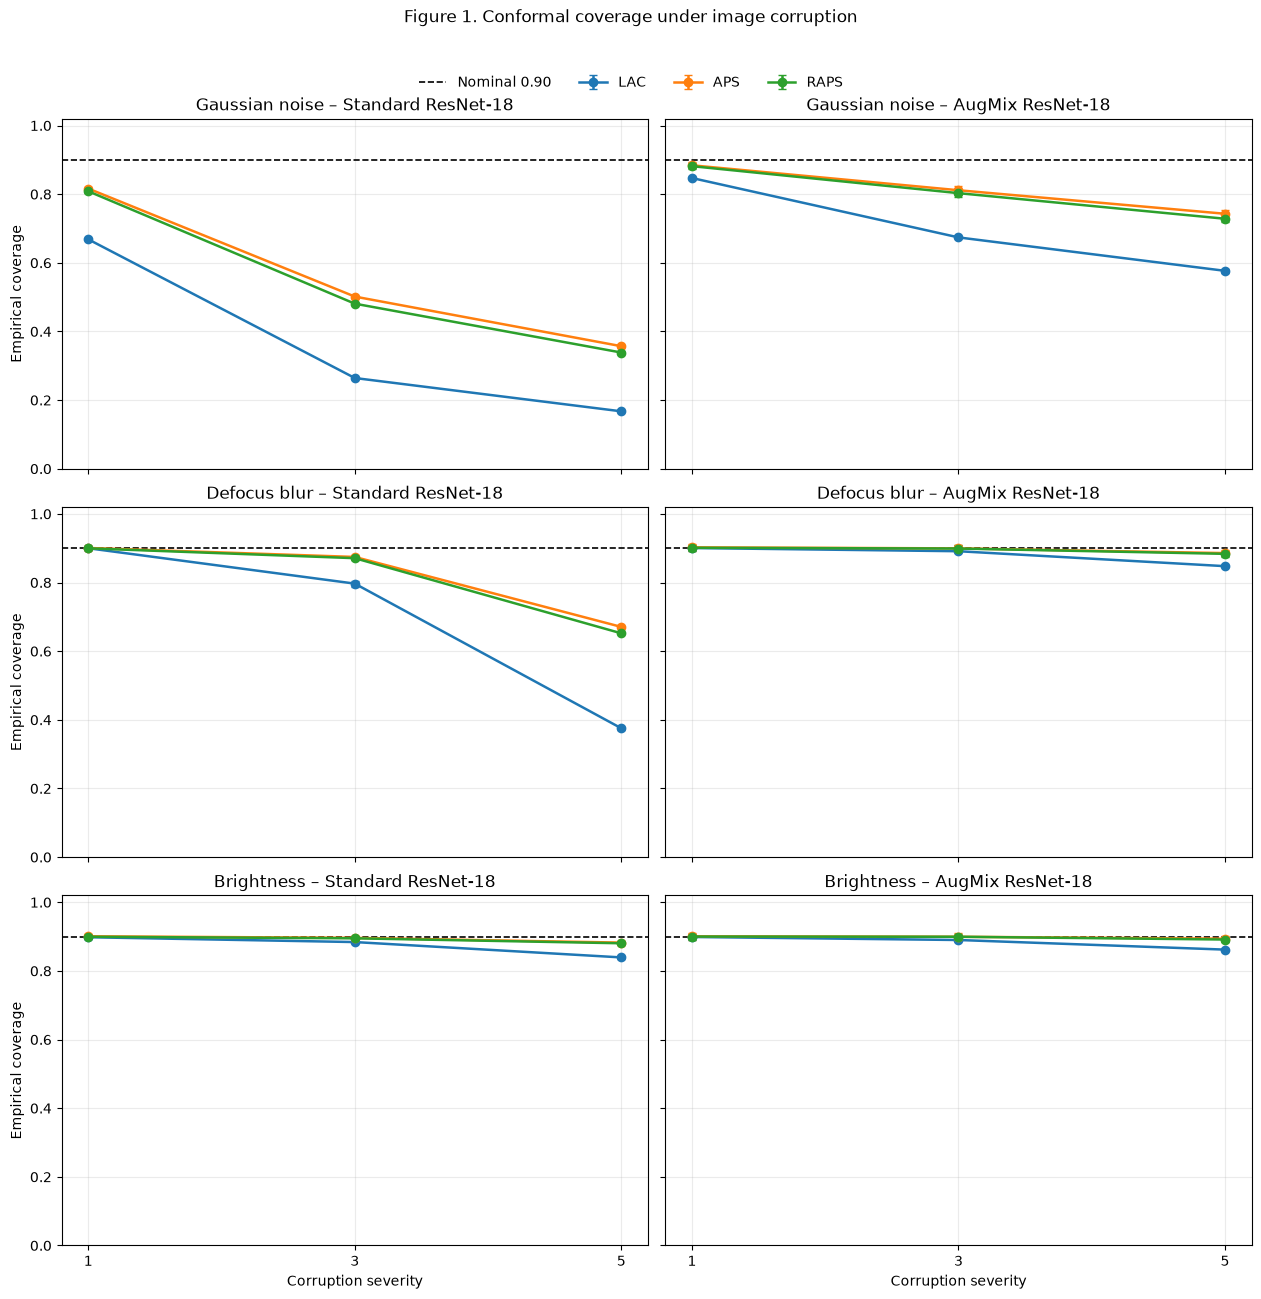

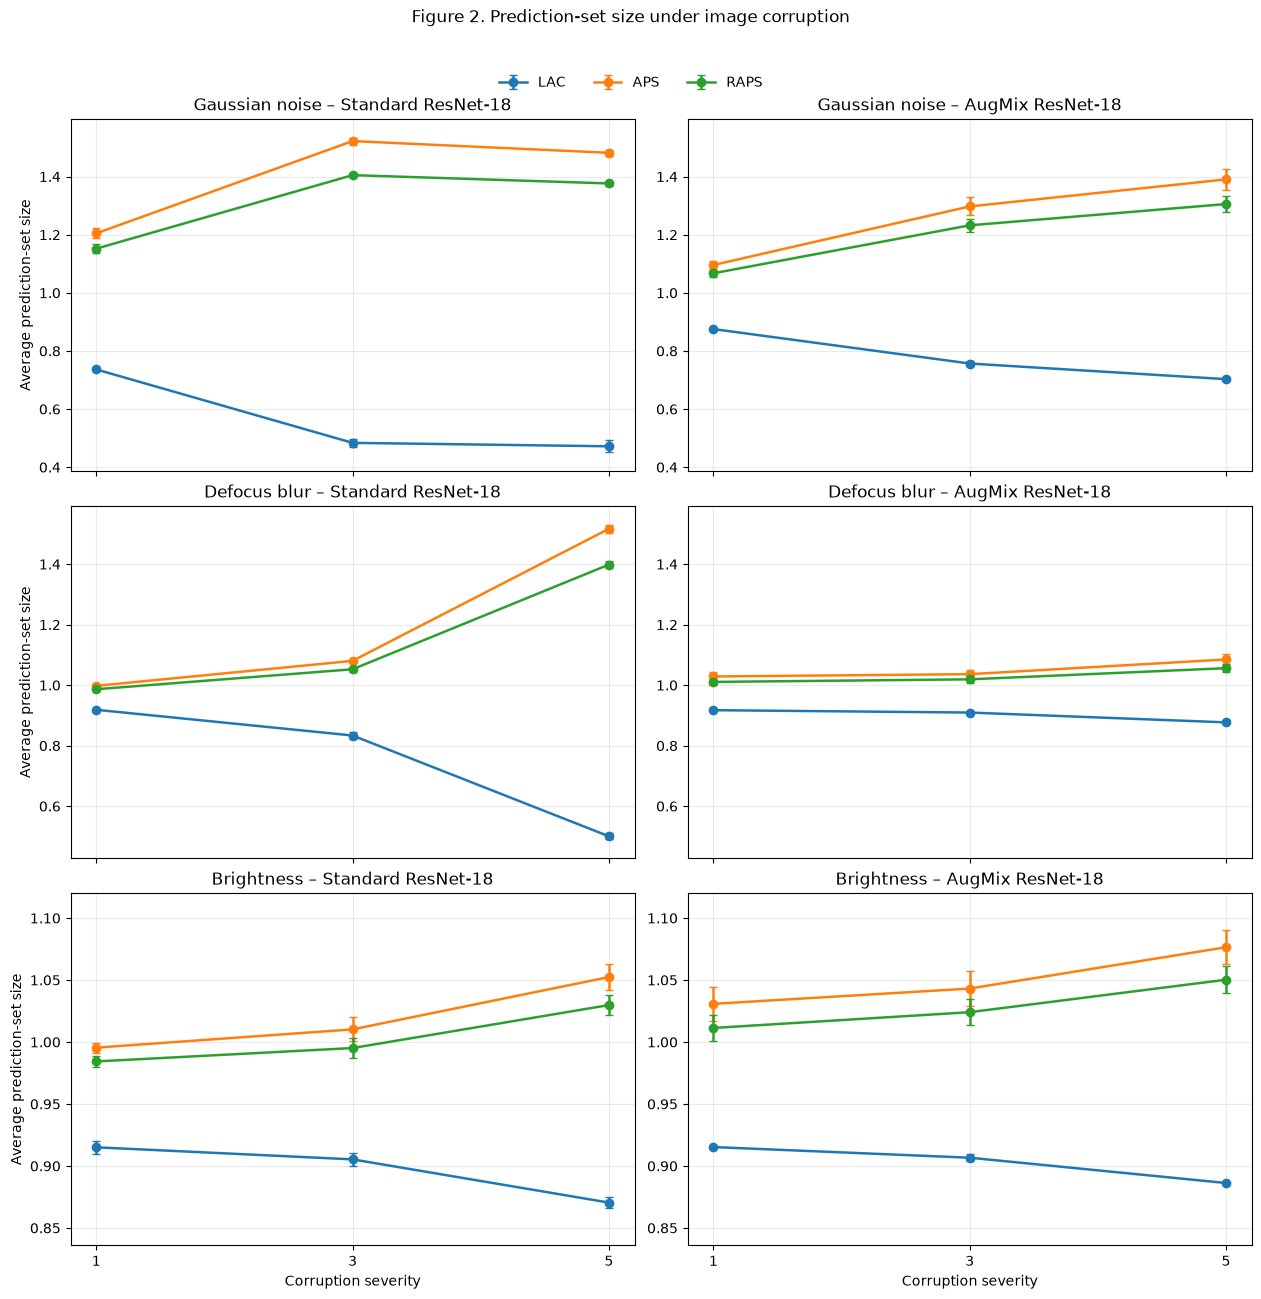

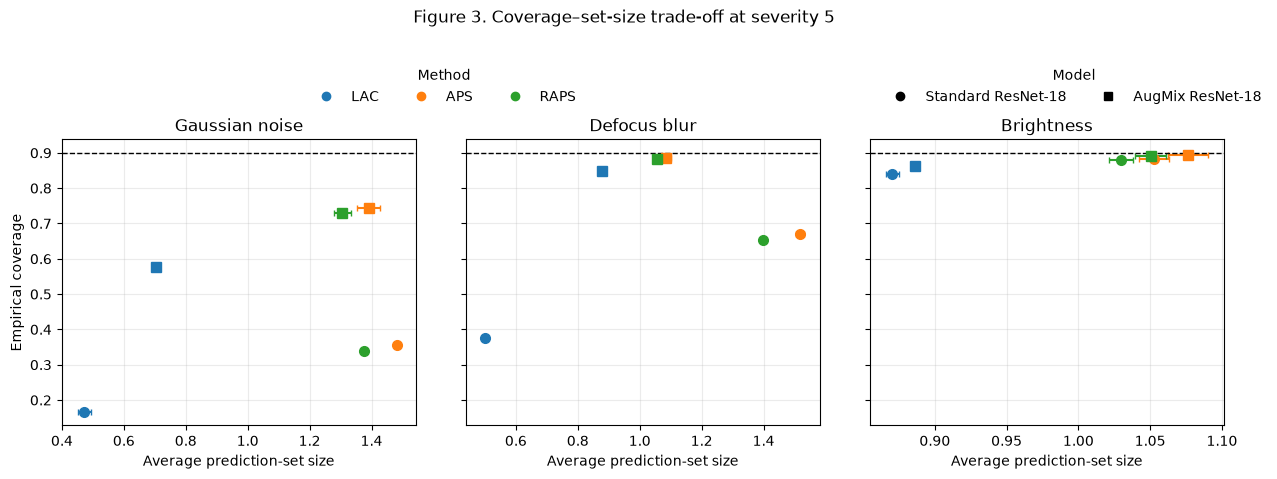

In [ ]:
def save_once(fig, stem):
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    png, pdf = FIGURES_DIR / f"{stem}.png", FIGURES_DIR / f"{stem}.pdf"
    exists = (png.exists(), pdf.exists())
    if any(exists) and not all(exists):
        raise FileExistsError(f"Incomplete prior figure pair for {stem}; inspect before changing.")

    if all(exists) and not REGENERATE_FIGURES:
        print(f"Retained existing {stem}.png and {stem}.pdf; REGENERATE_FIGURES=False")
        plt.show()
        plt.close(fig)
        return

    if all(exists):
        backup_stamp = datetime.now(timezone.utc).strftime("before_explicit_regeneration_%Y%m%dT%H%M%S_%fZ")
        backup_dir = FIGURE_BACKUP_ROOT / backup_stamp / stem
        backup_dir.mkdir(parents=True, exist_ok=False)
        for current in (png, pdf):
            backup = backup_dir / current.name
            if backup.exists():
                if backup.read_bytes() != current.read_bytes():
                    raise FileExistsError(f"Existing figure backup differs from current prior output: {backup}")
            else:
                shutil.copy2(current, backup)
            if backup.read_bytes() != current.read_bytes():
                raise IOError(f"Figure backup verification failed: {backup}")

    temp_png = FIGURES_DIR / f".{stem}.regenerating.png"
    temp_pdf = FIGURES_DIR / f".{stem}.regenerating.pdf"
    fig.savefig(temp_png, dpi=300, bbox_inches="tight", format="png")
    fig.savefig(temp_pdf, bbox_inches="tight", format="pdf")
    if not temp_png.is_file() or not temp_pdf.is_file() or temp_png.stat().st_size == 0 or temp_pdf.stat().st_size == 0:
        raise IOError(f"Figure generation did not produce both nonempty files for {stem}")
    temp_png.replace(png)
    temp_pdf.replace(pdf)
    action = "Regenerated" if all(exists) else "Saved"
    print(f"{action} {png.relative_to(PROJECT_ROOT)} and {pdf.relative_to(PROJECT_ROOT)}")
    if all(exists):
        print(f"Verified previous figure pair backed up under {backup_dir.relative_to(PROJECT_ROOT)}")
    plt.show()
    plt.close(fig)

# Figure 1: coverage under the three approved corruption types.
fig, axes = plt.subplots(3, 2, figsize=(12.5, 12), sharex=True, sharey=True, constrained_layout=True)
for r, condition in enumerate(CONDITIONS):
    for c, model in enumerate(MODELS):
        ax = axes[r, c]
        part = corruption_summary[(corruption_summary.condition == condition) & (corruption_summary.model_key == model)]
        for method in METHODS:
            series = part[part.method == method].sort_values("severity")
            ax.errorbar(series.severity, series.empirical_coverage_mean, yerr=series.empirical_coverage_std, marker="o", capsize=3, linewidth=1.8, color=method_colors[method], label=METHOD_LABELS[method])
        ax.axhline(NOMINAL_COVERAGE, linestyle="--", linewidth=1.2, color="black", label="Nominal 0.90" if r == 0 and c == 0 else None)
        ax.set_title(f"{CONDITION_LABELS[condition]} – {MODEL_LABELS[model]}")
        ax.set_xticks(SEVERITIES); ax.set_ylim(0, 1.02); ax.grid(alpha=0.25)
        if c == 0: ax.set_ylabel("Empirical coverage")
        if r == 2: ax.set_xlabel("Corruption severity")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.025))
fig.suptitle("Figure 1. Conformal coverage under image corruption", y=1.07)
save_once(fig, "figure1_corruption_coverage")

# Figure 2: average set size; each Standard/AugMix pair shares its row's scale.
fig, axes = plt.subplots(3, 2, figsize=(12.5, 12), sharex=True, sharey=False, constrained_layout=True)
for r, condition in enumerate(CONDITIONS):
    row_lows, row_highs = [], []
    for c, model in enumerate(MODELS):
        ax = axes[r, c]
        part = corruption_summary[(corruption_summary.condition == condition) & (corruption_summary.model_key == model)]
        for method in METHODS:
            series = part[part.method == method].sort_values("severity")
            means = series.average_set_size_mean.to_numpy(float)
            errors = series.average_set_size_std.to_numpy(float)
            row_lows.extend((means - errors).tolist())
            row_highs.extend((means + errors).tolist())
            ax.errorbar(series.severity, means, yerr=errors, marker="o", capsize=3, linewidth=1.8, color=method_colors[method], label=METHOD_LABELS[method])
        ax.set_title(f"{CONDITION_LABELS[condition]} – {MODEL_LABELS[model]}")
        ax.set_xticks(SEVERITIES); ax.grid(alpha=0.25)
        if c == 0: ax.set_ylabel("Average prediction-set size")
        if r == 2: ax.set_xlabel("Corruption severity")
    span = max(row_highs) - min(row_lows)
    margin = max(0.06 * span, 0.03)
    shared_ylim = (max(0.0, min(row_lows) - margin), max(row_highs) + margin)
    for ax in axes[r, :]:
        ax.set_ylim(*shared_ylim)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.025))
fig.suptitle("Figure 2. Prediction-set size under image corruption", y=1.07)
save_once(fig, "figure2_corruption_set_size")

# Figure 3: severity 5 coverage versus set size; color is method, marker is model.
model_markers = {"standard_resnet18": "o", "augmix_resnet18": "s"}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True, constrained_layout=False)
fig.subplots_adjust(top=0.73, bottom=0.18, wspace=0.14)
for ax, condition in zip(axes, CONDITIONS):
    part = severity5_summary[severity5_summary.condition == condition]
    for model in MODELS:
        for method in METHODS:
            row = part[(part.model_key == model) & (part.method == method)].iloc[0]
            ax.errorbar(row.average_set_size_mean, row.empirical_coverage_mean, xerr=row.average_set_size_std, yerr=row.empirical_coverage_std, marker=model_markers[model], linestyle="none", color=method_colors[method], markersize=7, capsize=2)
    ax.axhline(NOMINAL_COVERAGE, linestyle="--", linewidth=1.0, color="black")
    ax.set_title(CONDITION_LABELS[condition]); ax.set_xlabel("Average prediction-set size"); ax.grid(alpha=0.25)
axes[0].set_ylabel("Empirical coverage")
method_legend = [plt.Line2D([0], [0], marker="o", color=method_colors[m], linestyle="none", label=METHOD_LABELS[m]) for m in METHODS]
model_legend = [plt.Line2D([0], [0], marker=model_markers[m], color="black", linestyle="none", label=MODEL_LABELS[m]) for m in MODELS]
fig.legend(handles=method_legend, loc="upper center", bbox_to_anchor=(0.38, 0.89), ncol=3, frameon=False, title="Method")
fig.legend(handles=model_legend, loc="upper center", bbox_to_anchor=(0.80, 0.89), ncol=2, frameon=False, title="Model")
fig.suptitle("Figure 3. Coverage–set-size trade-off at severity 5", y=0.98)
save_once(fig, "figure3_severity5_coverage_setsize_tradeoff")


## 7. Illustrative class-pair contrasts

These panels show cat/dog and airplane/automobile as contrasting examples from the full 45-pair design. They retain the saved numerical results and fixed priors. The next section shows every pair, which supplies the overall label-shift comparison. Individual image predictions, prediction sets, and calibration thresholds remain fixed.

Retained existing figure4_label_shift_coverage.png and figure4_label_shift_coverage.pdf; REGENERATE_FIGURES=False
Retained existing figure5_class_conditional_coverage_heatmap.png and figure5_class_conditional_coverage_heatmap.pdf; REGENERATE_FIGURES=False


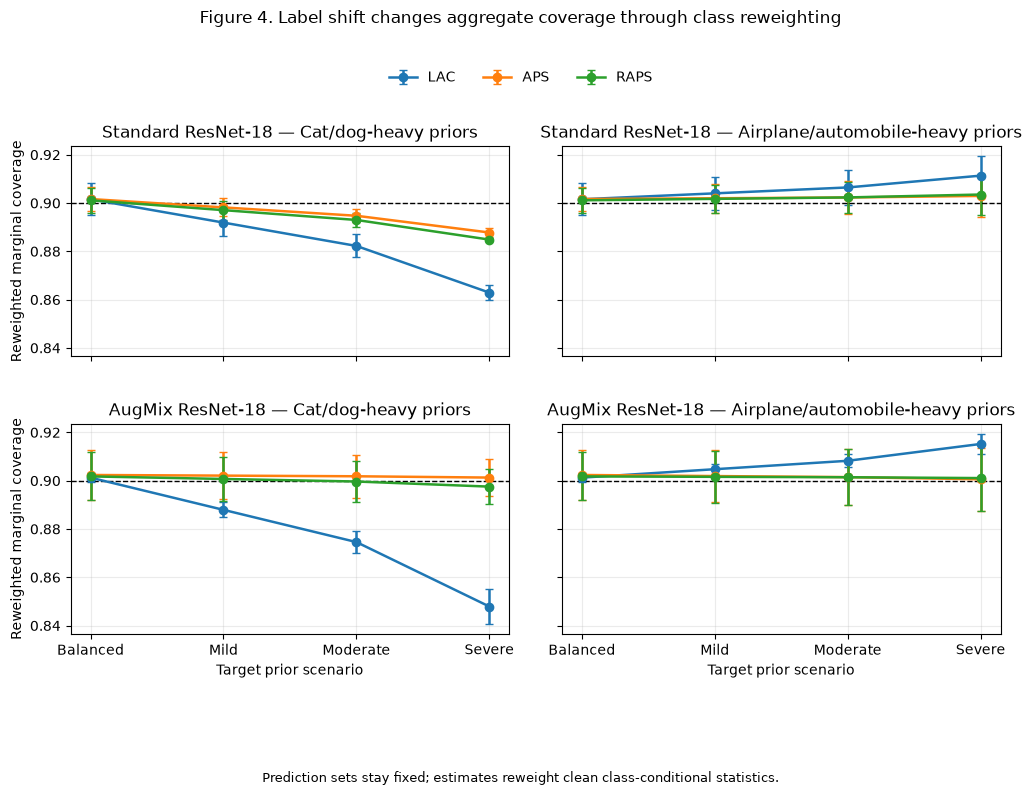

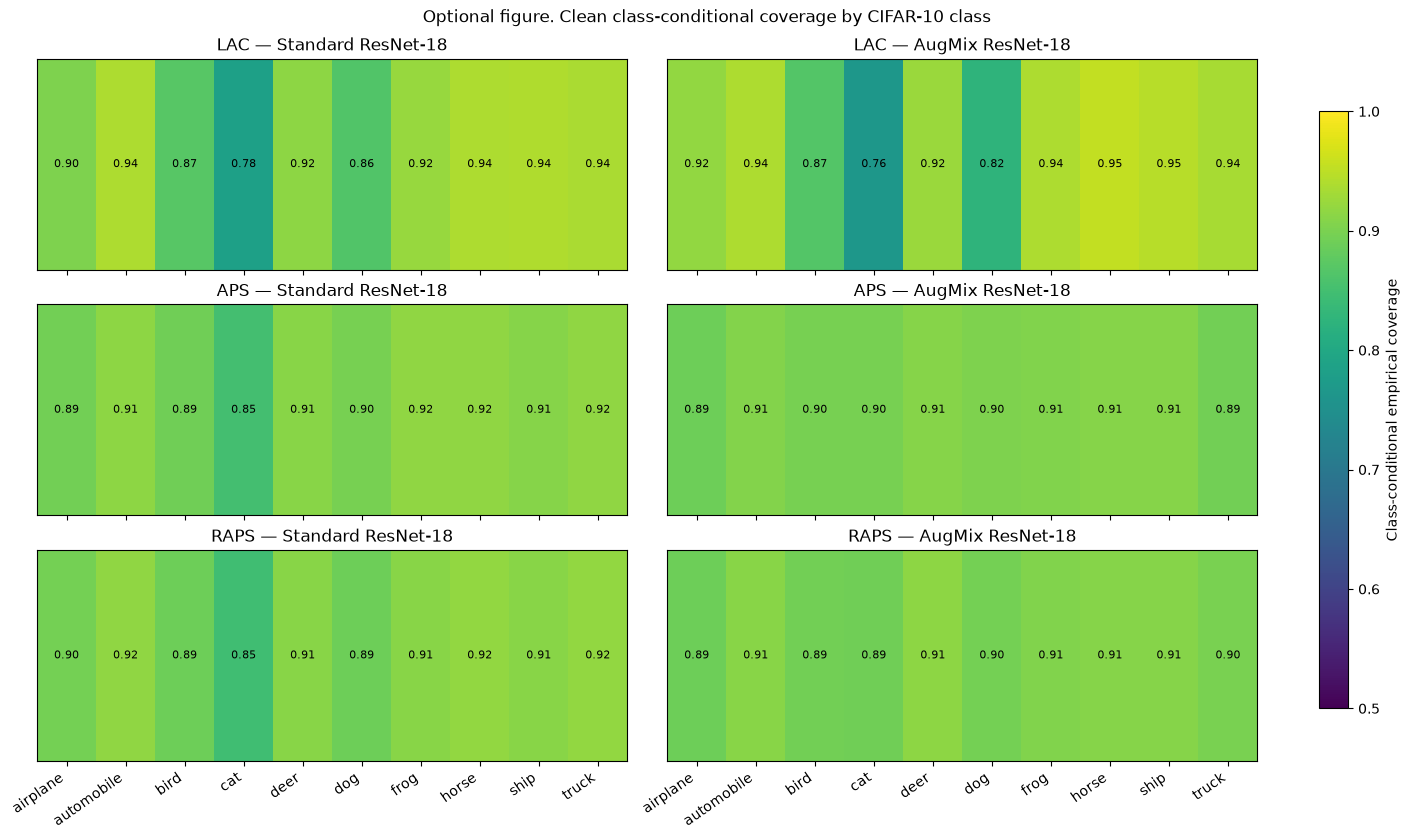

In [ ]:
# Figure 4: balanced, mild, moderate, and severe fixed priors.
families = ["cat_dog", "airplane_automobile"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True, constrained_layout=False)
fig.subplots_adjust(top=0.82, bottom=0.21, wspace=0.12, hspace=0.32)
for r, model in enumerate(MODELS):
    for c, family in enumerate(families):
        ax = axes[r, c]
        scenarios = (["balanced", "cat_dog_mild", "cat_dog_moderate", "cat_dog_severe"]
                     if family == "cat_dog" else
                     ["balanced", "airplane_automobile_mild", "airplane_automobile_moderate", "airplane_automobile_severe"])
        family_label = "Cat/dog-heavy priors" if family == "cat_dog" else "Airplane/automobile-heavy priors"
        for method in METHODS:
            part = label_summary[(label_summary.model_key == model) & (label_summary.method == method) & label_summary.scenario.isin(scenarios)].copy()
            part["scenario"] = pd.Categorical(part.scenario, categories=scenarios, ordered=True)
            part = part.sort_values("scenario")
            ax.errorbar(range(4), part.empirical_coverage_mean, yerr=part.empirical_coverage_std, marker="o", capsize=3, linewidth=1.8, color=method_colors[method], label=METHOD_LABELS[method])
        ax.axhline(NOMINAL_COVERAGE, linestyle="--", linewidth=1.0, color="black")
        ax.set_title(f"{MODEL_LABELS[model]} — {family_label}")
        ax.set_xticks(range(4), ["Balanced", "Mild", "Moderate", "Severe"]); ax.grid(alpha=0.25)
        if c == 0: ax.set_ylabel("Reweighted marginal coverage")
        if r == 1: ax.set_xlabel("Target prior scenario")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.93))
fig.suptitle("Figure 4. Label shift changes aggregate coverage through class reweighting", y=0.99)
fig.text(0.5, 0.025, "Prediction sets stay fixed; estimates reweight clean class-conditional statistics.", ha="center", fontsize=9)
save_once(fig, "figure4_label_shift_coverage")

# Optional Figure 5: class-conditional coverage helps explain the reweighted aggregates.
class_mean = class_conditional.groupby(["method", "model_key", "class_id", "class_name"], as_index=False).class_coverage.mean()
class_order = class_mean.sort_values("class_id").class_name.drop_duplicates().tolist()
fig, axes = plt.subplots(3, 2, figsize=(14, 8), sharex=True, sharey=True, constrained_layout=True)
for r, method in enumerate(METHODS):
    for c, model in enumerate(MODELS):
        ax = axes[r, c]
        part = class_mean[(class_mean.method == method) & (class_mean.model_key == model)].sort_values("class_id")
        values = part.class_coverage.to_numpy()[None, :]
        image = ax.imshow(values, aspect="auto", vmin=0.5, vmax=1.0)
        ax.set_yticks([]); ax.set_title(f"{method} — {MODEL_LABELS[model]}")
        ax.set_xticks(range(10), class_order, rotation=35, ha="right")
        for x, value in enumerate(values.ravel()):
            ax.text(x, 0, f"{value:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=axes, label="Class-conditional empirical coverage", shrink=0.85)
fig.suptitle("Optional figure. Clean class-conditional coverage by CIFAR-10 class", y=1.03)
save_once(fig, "figure5_class_conditional_coverage_heatmap")

## 8. Full label-shift rotation: all class pairs

The overview shows all 45 emphasized pairs at each shift level, for every model and conformal method. Each point is a mean over three overlapping split partitions. Cat/dog and airplane/automobile are highlighted as the two illustrative contrasts shown in Figure 4; the full enumeration supplies the overall result.

Equal averaging across all 45 priors gives the balanced prior, so mean coverage across pairs equals balanced coverage. The spread and the number of pair means below 0.90 describe which label mixtures lose coverage. The point cloud is not an independent-sample confidence interval. This section reads the saved rotation tables and manifest; it does not use model inference.

All 45 pairs are shown at each level; colored points identify the two illustrative contrasts.


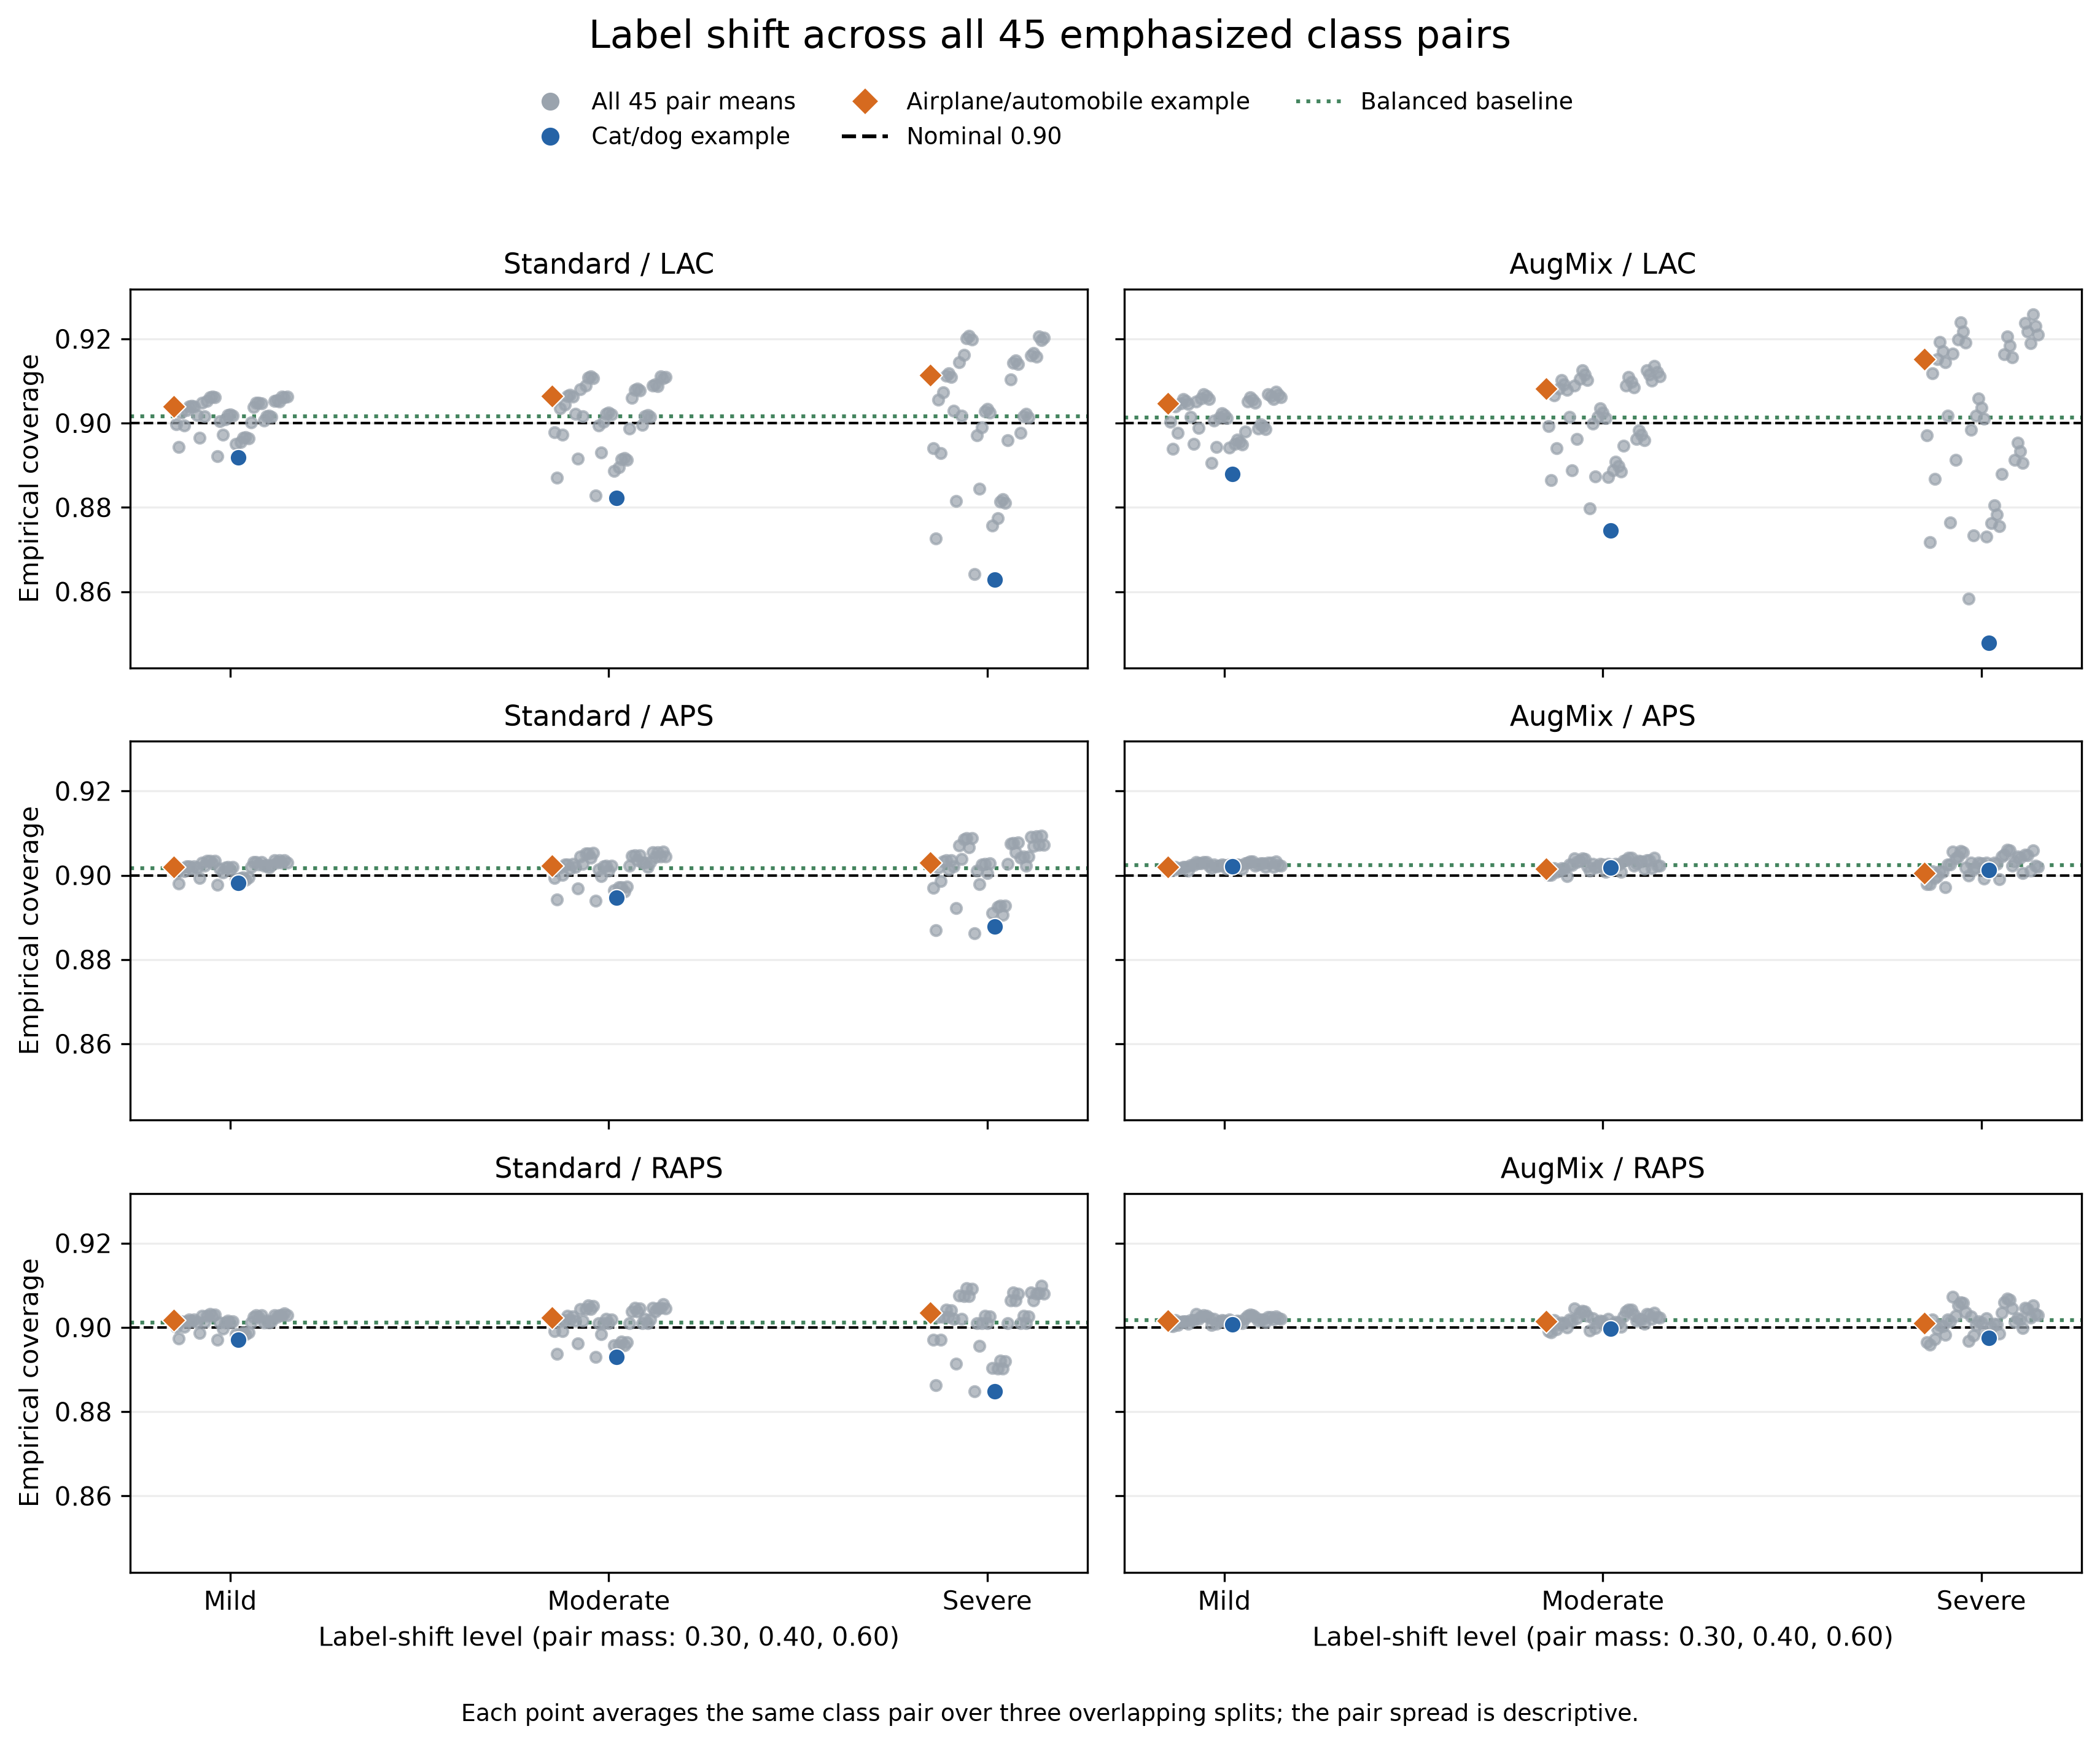

In [ ]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import Image, display

rotation_plot_root = next(
    (p.resolve() for p in (Path.cwd(), Path.cwd().parent)
     if (p / "results" / "label_shift_rotation_manifest.json").is_file()),
    None,
)
if rotation_plot_root is None:
    raise FileNotFoundError("Run the all-pair rotation section in Stage 8 first.")
rotation_plot_results = rotation_plot_root / "results"
rotation_plot_manifest = json.loads(
    (rotation_plot_results / "label_shift_rotation_manifest.json").read_text()
)
for name, expected in rotation_plot_manifest["output_sha256"].items():
    if hashlib.sha256((rotation_plot_results / name).read_bytes()).hexdigest() != expected:
        raise ValueError(f"Rotation table differs from its manifest: {name}")
rotation_plot_summary = pd.read_csv(
    rotation_plot_results / "label_shift_rotation_summary_mean_std.csv"
)
rotation_plot_overview = pd.read_csv(
    rotation_plot_results / "label_shift_rotation_overview.csv"
)
assert len(rotation_plot_summary) == 816 and len(rotation_plot_overview) == 18

rotation_plot_models = ["standard_resnet18", "augmix_resnet18"]
rotation_plot_methods = ["LAC", "APS", "RAPS"]
rotation_plot_levels = ["mild", "moderate", "severe"]
rotation_plot_colors = {"cat/dog": "#2563a6", "airplane/automobile": "#d66a1f"}
all_coverage = rotation_plot_summary.empirical_coverage_mean
rotation_y_limits = (
    min(0.90, float(all_coverage.min())) - 0.006,
    max(0.90, float(all_coverage.max())) + 0.006,
)
rotation_figure, rotation_axes = plt.subplots(
    3, 2, figsize=(11.5, 9.5), sharex=True, sharey=True
)
for row, method in enumerate(rotation_plot_methods):
    for col, model in enumerate(rotation_plot_models):
        ax = rotation_axes[row, col]
        part = rotation_plot_summary[
            (rotation_plot_summary.method == method)
            & (rotation_plot_summary.model_key == model)
        ]
        baseline = float(part.loc[part.severity == "balanced", "empirical_coverage_mean"].iloc[0])
        ax.axhline(0.90, color="black", linestyle="--", linewidth=1)
        ax.axhline(baseline, color="#43845e", linestyle=":", linewidth=1.5)
        for position, severity in enumerate(rotation_plot_levels):
            pairs = part[part.severity == severity].sort_values(
                ["pair_class_1", "pair_class_2"]
            ).reset_index(drop=True)
            assert len(pairs) == 45
            offsets = np.linspace(-0.15, 0.15, 45)
            ax.scatter(
                position + offsets, pairs.empirical_coverage_mean,
                color="#9aa3ad", alpha=0.70, s=17, zorder=2,
            )
            for first, second, label, marker in [
                (3, 5, "cat/dog", "o"), (0, 1, "airplane/automobile", "D")
            ]:
                selected = pairs.index[
                    (pairs.pair_class_1 == first) & (pairs.pair_class_2 == second)
                ][0]
                ax.scatter(
                    position + offsets[selected],
                    pairs.loc[selected, "empirical_coverage_mean"],
                    color=rotation_plot_colors[label], marker=marker,
                    s=43, edgecolor="white", linewidth=0.5, zorder=4,
                )
        model_label = "Standard" if col == 0 else "AugMix"
        ax.set_title(f"{model_label} / {method}", fontsize=11)
        ax.set_xticks(range(3), [level.capitalize() for level in rotation_plot_levels])
        ax.set_ylim(*rotation_y_limits)
        ax.grid(axis="y", alpha=0.22)
        if col == 0:
            ax.set_ylabel("Empirical coverage")
        if row == 2:
            ax.set_xlabel("Label-shift level (pair mass: 0.30, 0.40, 0.60)")
rotation_figure.suptitle("Label shift across all 45 emphasized class pairs", fontsize=15, y=0.985)
handles = [
    Line2D([], [], color="#9aa3ad", marker="o", linestyle="", label="All 45 pair means"),
    Line2D([], [], color=rotation_plot_colors["cat/dog"], marker="o", linestyle="", label="Cat/dog example"),
    Line2D([], [], color=rotation_plot_colors["airplane/automobile"], marker="D", linestyle="", label="Airplane/automobile example"),
    Line2D([], [], color="black", linestyle="--", label="Nominal 0.90"),
    Line2D([], [], color="#43845e", linestyle=":", label="Balanced baseline"),
]
rotation_figure.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.955), ncol=3, frameon=False, fontsize=9)
rotation_figure.text(
    0.5, 0.012,
    "Each point averages the same class pair over three overlapping splits; the pair spread is descriptive.",
    ha="center", fontsize=9,
)
rotation_figure.tight_layout(rect=(0, 0.035, 1, 0.905))
rotation_figure_dir = rotation_plot_root / "figures"
rotation_figure_dir.mkdir(parents=True, exist_ok=True)
rotation_stem = "figure6_label_shift_rotation_coverage"
rotation_png = rotation_figure_dir / f"{rotation_stem}.png"
rotation_pdf = rotation_figure_dir / f"{rotation_stem}.pdf"
if rotation_png.exists() != rotation_pdf.exists():
    raise FileExistsError("Incomplete full-rotation figure pair; inspect the two exports.")
if not rotation_png.exists() or globals().get("REGENERATE_FIGURES", False):
    rotation_figure.savefig(rotation_png, dpi=300, bbox_inches="tight")
    rotation_figure.savefig(rotation_pdf, bbox_inches="tight")
plt.close(rotation_figure)
print("All 45 pairs are shown at each level; colored points identify the two illustrative contrasts.")
display(Image(filename=str(rotation_png)))


## 9. Interpretation and limitations

Read coverage together with set size: larger sets can preserve more labels, while smaller means can coincide with more empty sets. Set size also depends on each method's score and set-construction rule, so it is not a pure uncertainty measure.

Compare Standard and AugMix only at matched corruption, severity, and conformal method. A difference here is an observation for this experiment, not a robustness guarantee. LAC, APS, and RAPS also have different score constructions; higher coverage alone does not establish universal superiority.

Under image corruption, report empirical undercoverage relative to 0.90 when observed. The usual exchangeability-based split-conformal guarantee does not directly apply after the evaluation distribution changes.

Under label shift, the analytical aggregate can increase or decrease depending on which classes receive more weight and their class-conditional coverage. Reweighting does not alter any individual prediction set. The estimates use finite clean evaluation samples and assume class-conditional image distributions remain unchanged.

Mean ± sample SD describes the three overlapping split sensitivity checks; it is not an independent-replication confidence interval.

For the complete label-shift rotation, equal averaging over all 45 emphasized pairs exactly returns balanced metrics. This follows from symmetry of the target priors, rather than evidence that every label mixture behaves alike. Report the range and distribution of pair outcomes with the mean; the pair outcomes share the same images and are not independent replications.

## 10. Save tables and compact provenance

This section verifies existing Stage 9 tables against the recomputed summaries and writes missing outputs under `results/`. Compact provenance consists of the Stage 4 cache manifest and accuracy summary, model metadata, and training configurations. The committed copies in `results/` support a clone without cache or checkpoint folders.

The two class-group contrast tables are derived from Stage 8 class-conditional metrics and fixed priors. Stage 4-8 experimental CSVs remain read-only inputs.

In [ ]:
def csv_tables_match(path, frame):
    existing = pd.read_csv(path)
    expected = frame.reset_index(drop=True)
    existing.columns.name = None
    expected.columns.name = None
    if list(existing.columns) != list(expected.columns):
        return False
    existing = existing.sort_values(list(existing.columns), na_position="last").reset_index(drop=True)
    expected = expected.sort_values(list(expected.columns), na_position="last").reset_index(drop=True)
    try:
        pd.testing.assert_frame_equal(existing, expected, check_dtype=False, check_exact=False, rtol=1e-12, atol=1e-12)
        return True
    except AssertionError:
        return False

def write_csv_once(frame, path):
    path = Path(path)
    if path.exists():
        if not csv_tables_match(path, frame):
            raise FileExistsError(f"Existing output differs; inspect before replacing: {path}")
        print(f"Verified existing table: {path.relative_to(PROJECT_ROOT)}")
    else:
        frame.to_csv(path, index=False)
        print(f"Saved {path.relative_to(PROJECT_ROOT)}")

def write_corrected_group_table(frame, path, filename):
    path = Path(path)
    if not path.exists():
        frame.to_csv(path, index=False)
        print(f"Saved corrected derived table: {path.relative_to(PROJECT_ROOT)}")
        return
    if csv_tables_match(path, frame):
        print(f"Verified corrected derived table: {path.relative_to(PROJECT_ROOT)}")
        return

    backup_dir = RESULTS_DIR / "archive" / "stage9_pre_group_contrast_fix"
    backup_dir.mkdir(parents=True, exist_ok=True)
    backup = backup_dir / filename
    if backup.exists():
        if backup.read_bytes() != path.read_bytes():
            raise FileExistsError(f"Prior derived-table backup differs from the current prior output: {backup}")
    else:
        shutil.copy2(path, backup)
    if backup.read_bytes() != path.read_bytes():
        raise IOError(f"Prior derived-table backup verification failed: {backup}")

    temp_path = path.with_name(f".{path.name}.correcting")
    frame.to_csv(temp_path, index=False)
    if not csv_tables_match(temp_path, frame):
        raise IOError(f"Corrected table verification failed before replacement: {temp_path}")
    temp_path.replace(path)
    print(f"Corrected derived table; verified prior copy at {backup.relative_to(PROJECT_ROOT)}")

def copy_once(source, destination):
    source, destination = Path(source), Path(destination)
    if source.resolve() == destination.resolve():
        if not destination.is_file():
            raise FileNotFoundError(destination)
        return
    if destination.exists():
        if source.read_bytes() != destination.read_bytes():
            raise FileExistsError(f"Existing provenance copy differs: {destination}")
    else:
        shutil.copy2(source, destination)

outputs = {
    "stage9_clean_split_metrics.csv": clean_split_metrics,
    "stage9_clean_summary_mean_std.csv": clean_summary,
    "stage9_corruption_split_metrics.csv": corruption_split_metrics,
    "stage9_corruption_summary_mean_std.csv": corruption_summary,
    "stage9_severity5_comparison.csv": severity5_summary,
    "stage9_label_shift_main_scenarios.csv": label_summary_main,
    "stage9_class_conditional_group_contrasts_split.csv": group_split,
    "stage9_class_conditional_group_contrasts_summary.csv": group_summary,
}
for filename, frame in outputs.items():
    path = RESULTS_DIR / filename
    if filename in {"stage9_class_conditional_group_contrasts_split.csv", "stage9_class_conditional_group_contrasts_summary.csv"}:
        write_corrected_group_table(frame, path, filename)
    else:
        write_csv_once(frame, path)

compact_sources = {
    "stage4_cache_manifest.json": (CACHE_DIR / "cache_manifest.json", RESULTS_DIR / "stage4_cache_manifest.json"),
    "stage4_cache_accuracy_summary.csv": (CACHE_DIR / "cache_accuracy_summary.csv", RESULTS_DIR / "stage4_cache_accuracy_summary.csv"),
    "model_metadata_standard_resnet18.json": (CACHE_DIR / "standard_resnet18" / "model_metadata.json", RESULTS_DIR / "model_metadata_standard_resnet18.json"),
    "model_metadata_augmix_resnet18.json": (CACHE_DIR / "augmix_resnet18" / "model_metadata.json", RESULTS_DIR / "model_metadata_augmix_resnet18.json"),
    "training_config_standard_resnet18.json": (PROJECT_ROOT / "checkpoints" / "resnet18_standard_colab" / "training_config.json", RESULTS_DIR / "training_config_standard_resnet18.json"),
    "training_config_augmix_resnet18.json": (PROJECT_ROOT / "checkpoints" / "resnet18_augmix_colab" / "training_config.json", RESULTS_DIR / "training_config_augmix_resnet18.json"),
}
compact_artifacts = {}
for filename, (primary, fallback) in compact_sources.items():
    source = primary if primary.is_file() else fallback
    if not source.is_file():
        raise FileNotFoundError(f"Compact provenance is missing from both preferred and results locations: {filename}")
    destination = RESULTS_DIR / filename
    copy_once(source, destination)
    compact_artifacts[filename] = destination

hash_inputs = {
    "stage4_cache_accuracy_summary.csv": src["cache_accuracy"],
    "lac_clean_metrics.csv": src["clean"]["LAC"],
    "aps_clean_metrics.csv": src["clean"]["APS"],
    "raps_clean_metrics.csv": src["clean"]["RAPS"],
    "lac_corruption_metrics.csv": src["corruption"]["LAC"],
    "aps_corruption_metrics.csv": src["corruption"]["APS"],
    "raps_corruption_metrics.csv": src["corruption"]["RAPS"],
    "label_shift_split_results.csv": src["label_split"],
    "label_shift_summary_mean_std.csv": src["label_summary"],
    "label_shift_class_conditional_metrics.csv": src["class_conditional"],
    "label_shift_target_priors.csv": src["target_priors"],
    "label_shift_baseline_reconstruction_audit.csv": src["baseline_audit"],
    "label_shift_monte_carlo_validation.csv": src["monte_carlo"],
}
for rotation_name in (
    "label_shift_rotation_target_priors.csv", "label_shift_rotation_split_results.csv",
    "label_shift_rotation_summary_mean_std.csv", "label_shift_rotation_overview.csv",
    "label_shift_rotation_manifest.json",
):
    hash_inputs[rotation_name] = RESULTS_DIR / rotation_name
source_hashes = {name: hashlib.sha256(path.read_bytes()).hexdigest() for name, path in hash_inputs.items()}
metadata_hashes = {f"results/{name}": hashlib.sha256(path.read_bytes()).hexdigest() for name, path in compact_artifacts.items()}
manifest = {
    "project": "Conformal Coverage Under Distribution Shift on CIFAR-10",
    "stage": 9, "nominal_coverage": NOMINAL_COVERAGE, "models": MODELS, "methods": METHODS,
    "split_seeds": SPLIT_SEEDS, "corruptions": CONDITIONS, "severities": SEVERITIES,
    "target_priors": {name: rows.sort_values("class_id").target_probability.astype(float).tolist() for name, rows in target_priors.groupby("scenario")},
    "source_sha256": source_hashes,
    "compact_metadata_sha256": metadata_hashes,
    "audit": {"cache_rows": 20, "clean_rows": 18, "corruption_rows": 162, "label_shift_split_rows": 126, "class_conditional_rows": 180, "baseline_rows": 18, "baseline_passed": True, "split_indices_disjoint_and_complete": True, "group_contrast_rows": 36, "group_contrast_summary_rows": 12, "group_partition_and_coverage_identity_passed": True},
    "derived_analysis_correction": "Corrected Stage 9 class-conditional group contrasts so each emphasized pair is compared with its own complementary eight classes; Stage 8 experiment results are unchanged.",
    "generated_tables": list(outputs),
    "figures": ["figure1_corruption_coverage", "figure2_corruption_set_size", "figure3_severity5_coverage_setsize_tradeoff", "figure4_label_shift_coverage", "figure5_class_conditional_coverage_heatmap"],
    "figure_regeneration": {"explicit_option": "REGENERATE_FIGURES", "default": False, "backup_directory": "figures/backups/before_explicit_regeneration_<UTC timestamp>/<figure stem>"},
    "scope": "No training, inference, recalibration, hyperparameter tuning, or new shifts in Stage 9.",
    "split_note": "Three overlapping splits are sensitivity checks, not independent experimental replications.",
}
manifest["figures"].append("figure6_label_shift_rotation_coverage")
rotation_metadata = json.loads((RESULTS_DIR / "label_shift_rotation_manifest.json").read_text())
manifest["label_shift_rotation"] = {key: rotation_metadata[key] for key in (
    "pair_count", "scenario_count_including_balanced", "split_result_rows",
    "scenario_summary_rows", "overview_rows", "prior_rows",
    "all_pair_mean_equals_balanced", "original_example_max_absolute_error",
)}
manifest_path = RESULTS_DIR / "stage9_analysis_manifest.json"
manifest_text = json.dumps(manifest, indent=2, ensure_ascii=False) + "\n"
if manifest_path.exists():
    old_text = manifest_path.read_text(encoding="utf-8")
    if old_text != manifest_text:
        backup_dir = RESULTS_DIR / "archive" / "stage9_manifest_history"
        backup_dir.mkdir(parents=True, exist_ok=True)
        prior_digest = hashlib.sha256(old_text.encode("utf-8")).hexdigest()[:12]
        backup = backup_dir / f"stage9_analysis_manifest_{prior_digest}.json"
        if backup.exists():
            if backup.read_text(encoding="utf-8") != old_text:
                raise FileExistsError(f"Content-addressed prior manifest backup differs: {backup}")
        else:
            shutil.copy2(manifest_path, backup)
        if backup.read_text(encoding="utf-8") != old_text:
            raise IOError(f"Prior manifest backup verification failed: {backup}")
        manifest_path.write_text(manifest_text, encoding="utf-8")
        print(f"Updated Stage 9 manifest; verified prior copy at {backup.relative_to(PROJECT_ROOT)}")
    else:
        print("Verified existing Stage 9 manifest.")
else:
    manifest_path.write_text(manifest_text, encoding="utf-8")
    print("Saved results/stage9_analysis_manifest.json.")
print("Original Stage 4–8 experimental CSVs were not changed.")


Verified existing table: results\stage9_clean_split_metrics.csv
Verified existing table: results\stage9_clean_summary_mean_std.csv
Verified existing table: results\stage9_corruption_split_metrics.csv
Verified existing table: results\stage9_corruption_summary_mean_std.csv
Verified existing table: results\stage9_severity5_comparison.csv
Verified existing table: results\stage9_label_shift_main_scenarios.csv
Verified corrected derived table: results\stage9_class_conditional_group_contrasts_split.csv
Verified corrected derived table: results\stage9_class_conditional_group_contrasts_summary.csv
Verified existing Stage 9 manifest.
Original Stage 4–8 experimental CSVs were not changed.


## 11. Final traceability checks

Verify saved summaries, source mappings, compact provenance, and the class-group identities linking balanced and severe label-shift coverage. Recreate the three Stage 1 split partitions in memory from seeds 42, 43, and 44 and check disjointness and full index coverage.

Stage 4-8 CSVs and compact metadata in `results/` are sufficient for this notebook. Raw datasets, saved split files, inference caches, trained weights, and recoverable training checkpoints are not needed.

In [ ]:
for filename in outputs:
    assert (RESULTS_DIR / filename).is_file()
for stem in manifest["figures"]:
    assert (FIGURES_DIR / f"{stem}.png").is_file()
    assert (FIGURES_DIR / f"{stem}.pdf").is_file()
for model in MODELS:
    metadata = json.loads((RESULTS_DIR / f"model_metadata_{model}.json").read_text(encoding="utf-8"))
    cache_row = cache_accuracy[(cache_accuracy.model_key == model) & (cache_accuracy.condition == "clean")]
    assert len(cache_row) == 1 and metadata["checkpoint_sha256"] == cache_row.iloc[0].checkpoint_sha256

saved_clean = pd.read_csv(RESULTS_DIR / "stage9_clean_split_metrics.csv")
saved_corruption = pd.read_csv(RESULTS_DIR / "stage9_corruption_split_metrics.csv")
saved_label = pd.read_csv(RESULTS_DIR / "stage9_label_shift_main_scenarios.csv")
saved_groups = pd.read_csv(RESULTS_DIR / "stage9_class_conditional_group_contrasts_split.csv")
saved_group_summary = pd.read_csv(RESULTS_DIR / "stage9_class_conditional_group_contrasts_summary.csv")
assert len(saved_clean) == 18 and len(saved_corruption) == 162 and len(saved_label) == 42
assert len(saved_groups) == 36 and len(saved_group_summary) == 12
assert np.allclose(saved_clean.empirical_coverage, clean_split_metrics.empirical_coverage)
assert np.allclose(saved_corruption.empirical_coverage, corruption_split_metrics.empirical_coverage)
assert np.allclose(saved_label.empirical_coverage_mean, label_summary_main.empirical_coverage_mean)
assert saved_groups.identity_absolute_error.max() < 1e-12
assert saved_group_summary.identity_absolute_error_mean.max() < 1e-12
for _, row in saved_groups.iterrows():
    emphasized = set(map(int, row.emphasized_class_ids.split(";")))
    complementary = set(map(int, row.complementary_eight_class_ids.split(";")))
    assert len(emphasized) == 2 and len(complementary) == 8
    assert emphasized.isdisjoint(complementary) and emphasized | complementary == set(range(10))
print("Final file, metadata, source-table, group-partition, and label-shift identity checks: PASS")
print(f"Figures: {len(manifest['figures'])} stems × PNG/PDF")
print(f"Derived tables: {len(outputs)}")
print(f"Results directory: {RESULTS_DIR}")


Final file, metadata, source-table, group-partition, and label-shift identity checks: PASS
Figures: 6 stems × PNG/PDF
Derived tables: 8
Results directory: E:\unc\2026f\store566\final project\results
